# ENSEMBLE LEARNING

In [17]:
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import matplotlib.pyplot as plt
%matplotlib inline

import warnings
warnings.filterwarnings('ignore')


In [2]:
from sklearn.datasets import fetch_openml

elec_data = fetch_openml(name='electricity', version=1)
elec_df = elec_data.frame

print("Data shape:", elec_data.data.shape)
print("Feature names:", elec_data.feature_names)
print("Target names:", elec_data.target_names)


Data shape: (45312, 8)
Feature names: ['date', 'day', 'period', 'nswprice', 'nswdemand', 'vicprice', 'vicdemand', 'transfer']
Target names: ['class']


In [3]:
from sklearn.model_selection import train_test_split

train_data, test_data = train_test_split(
    elec_df, test_size=0.25, random_state=20
)

print("Training samples:", len(train_data))
print("Testing samples:", len(test_data))


Training samples: 33984
Testing samples: 11328


In [4]:
train_data.head(10)


,date,day,period,nswprice,nswdemand,vicprice,vicdemand,transfer,class
27325,0.469846,4,0.276596,0.164705,0.519637,0.011417,0.657949,0.265789,DOWN
28731,0.474227,5,0.574468,0.024919,0.191907,0.001656,0.090886,0.819737,DOWN
8450,0.023141,3,0.042553,0.065270,0.250074,0.003467,0.422915,0.414912,DOWN
36659,0.889385,2,0.744681,0.148193,0.670039,0.009981,0.533402,0.563596,UP
781,0.000708,4,0.276596,0.124204,0.475454,0.003467,0.422915,0.414912,UP
13013,0.428963,7,0.106383,0.055242,0.084647,0.003467,0.422915,0.414912,DOWN
3330,0.009203,1,0.382979,0.045635,0.741892,0.003467,0.422915,0.414912,DOWN
18851,0.446662,2,0.744681,0.183409,0.785034,0.012154,0.757639,0.517105,UP
14838,0.433830,3,0.127660,0.047886,0.141476,0.003467,0.422915,0.414912,DOWN
30462,0.868236,6,0.638298,0.030833,0.702023,0.001963,0.538322,0.674123,UP


In [7]:
train_data.info()

<class 'pandas.DataFrame'>
Index: 33984 entries, 27325 to 27098
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype   
---  ------     --------------  -----   
 0   date       33984 non-null  float64 
 1   day        33984 non-null  category
 2   period     33984 non-null  float64 
 3   nswprice   33984 non-null  float64 
 4   nswdemand  33984 non-null  float64 
 5   vicprice   33984 non-null  float64 
 6   vicdemand  33984 non-null  float64 
 7   transfer   33984 non-null  float64 
 8   class      33984 non-null  category
dtypes: category(2), float64(7)
memory usage: 2.1 MB


In [8]:
train_data.describe()


,date,period,nswprice,nswdemand,vicprice,vicdemand,transfer
count,33984.000000,33984.000000,33984.000000,33984.000000,33984.000000,33984.000000,33984.000000
mean,0.498150,0.499211,0.057922,0.424763,0.003445,0.423035,0.500089
std,0.340429,0.294571,0.040195,0.163858,0.008846,0.121087,0.153224
min,0.000000,0.000000,0.000000,0.001190,0.000000,0.000000,0.000000
25%,0.031857,0.234043,0.035247,0.307944,0.002283,0.372087,0.414912
50%,0.456307,0.489362,0.048667,0.442725,0.003467,0.422915,0.414912
75%,0.880581,0.744681,0.074276,0.535704,0.003467,0.469446,0.605263
max,1.000000,1.000000,0.981806,1.000000,1.000000,1.000000,1.000000


In [9]:
train_data.isnull().sum()


date         0
day          0
period       0
nswprice     0
nswdemand    0
vicprice     0
vicdemand    0
transfer     0
class        0
dtype: int64

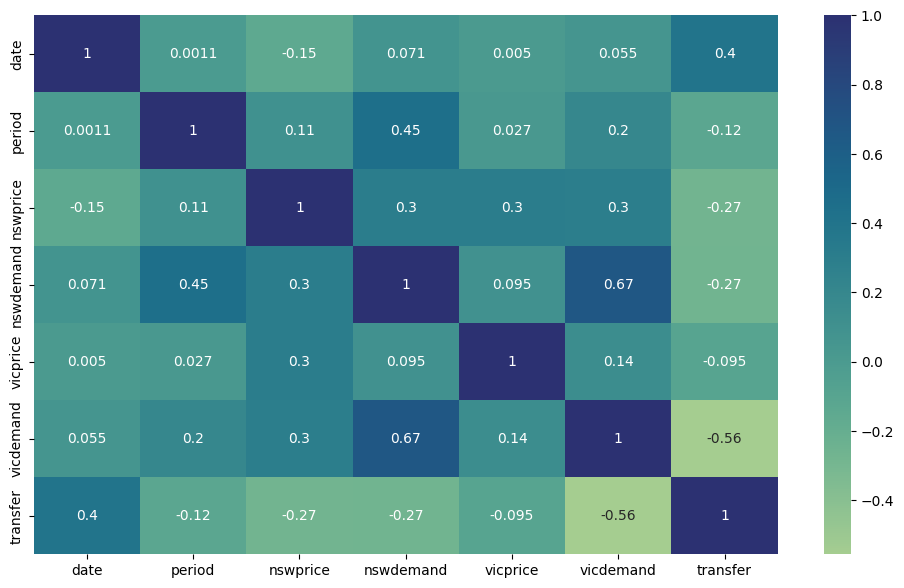

In [10]:
corr = train_data.corr(numeric_only=True)

plt.figure(figsize=(12, 7))
sns.heatmap(corr, annot=True, cmap='crest')
plt.show()


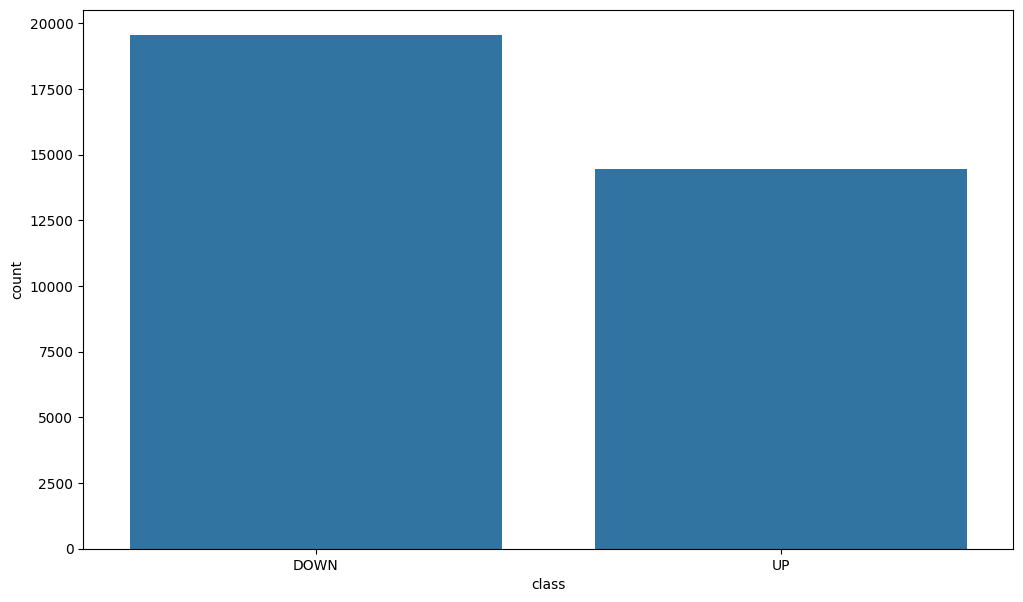

In [11]:
plt.figure(figsize=(12, 7))
sns.countplot(data=train_data, x='class')
plt.show()


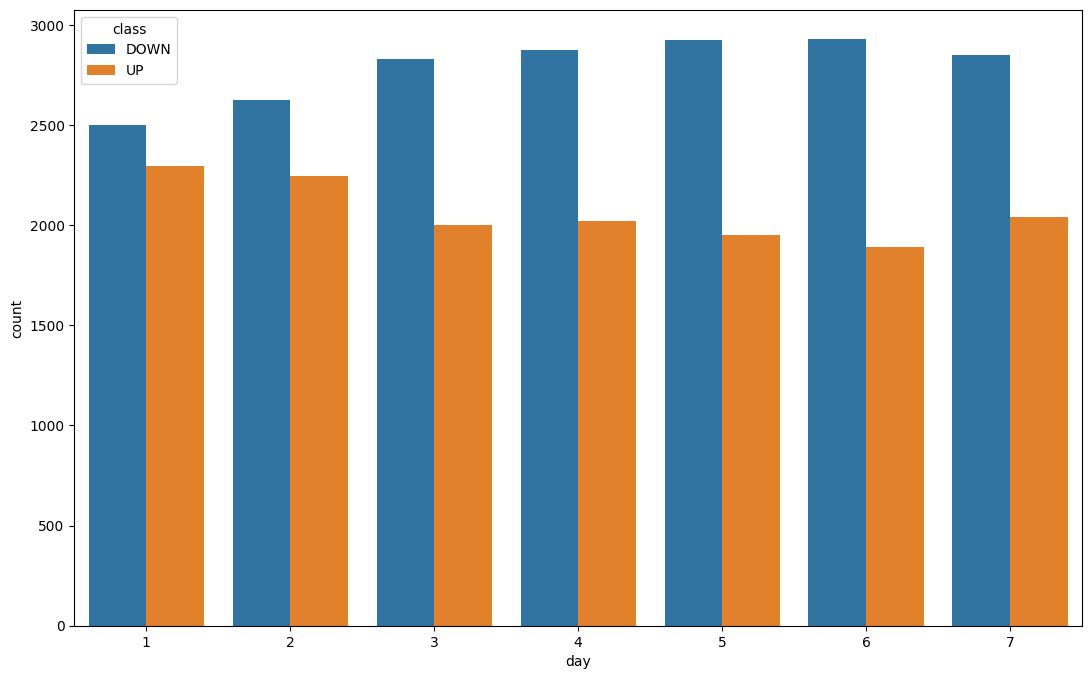

In [12]:
plt.figure(figsize=(13, 8))
sns.countplot(data=train_data, x='day', hue='class')
plt.show()


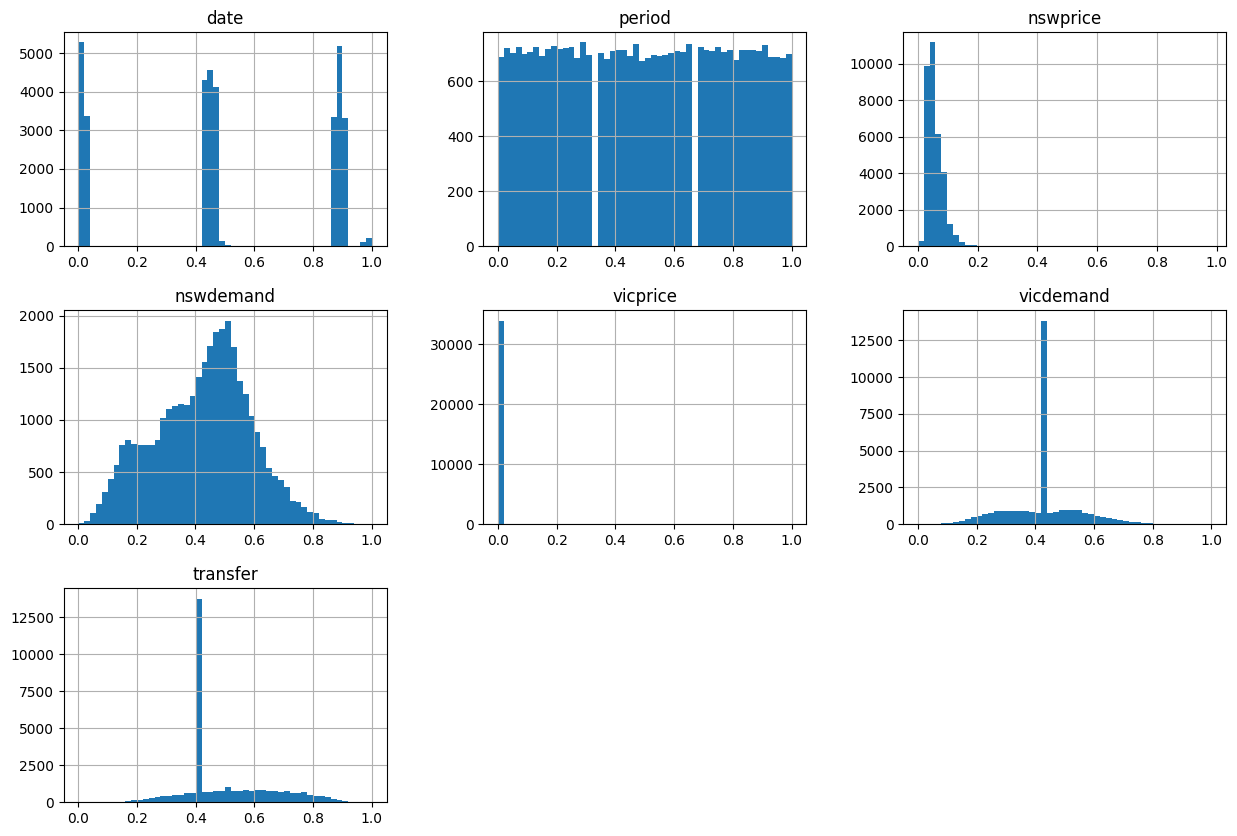

In [13]:
train_data.hist(bins=50, figsize=(15, 10))
plt.show()

In [14]:
from sklearn.preprocessing import LabelEncoder

X_train = train_data.drop('class', axis=1)
y_train = train_data['class']

label_enc = LabelEncoder()
y_train_prepared = label_enc.fit_transform(y_train)

print(label_enc.classes_)


['DOWN' 'UP']


In [15]:
from sklearn.metrics import accuracy_score

def accuracy(model, data, labels):
    predictions = model.predict(data)
    acc = accuracy_score(labels, predictions)

    return acc


In [16]:
from sklearn.ensemble import VotingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

# day is a category of strings, so we make a numeric copy
X_train_num = X_train.copy()
X_train_num['day'] = X_train_num['day'].astype(int)
models = [('lr', LogisticRegression(max_iter=1000)),
          ('rf', RandomForestClassifier(n_estimators=100, random_state=42)),
          ('svc', SVC(probability=True, random_state=42))]

voting_hard = VotingClassifier(models, voting='hard')
voting_soft = VotingClassifier(models, voting='soft')
voting_hard.fit(X_train_num, y_train_prepared)
voting_soft.fit(X_train_num, y_train_prepared)
print(accuracy(voting_hard, X_train_num, y_train_prepared))
print(accuracy(voting_soft, X_train_num, y_train_prepared))


0.8177083333333334
0.9141949152542372
